# Feature analysis: which recent-call lags to use

We look for useful lags on the training years only (2022–2024), so the choice does not depend on validation or test data.
The forecast is made on Thursday morning, when the latest complete shift is Wednesday's, so lags 1 and 2 are shown but cannot be used as features.

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from sklearn.feature_selection import mutual_info_regression

# this notebook is in notebooks/, so data and figures are one folder up
df = pd.read_csv('../data/station_shift_counts.csv', parse_dates=['ShiftDate'])
df = df.sort_values(['Station', 'ShiftDate']).reset_index(drop=True)
df['known'] = df['calls'].where(~df['Masked'])          # outage shifts count as unknown
train = df[df['ShiftDate'].dt.year <= 2024].copy()       # look for lags on training years only

# citywide series: one value per shift, unknown on outage shifts
city = train.groupby('ShiftDate')['known'].sum(min_count=34)
city[train.groupby('ShiftDate')['Masked'].any()] = np.nan
print(f"{len(city)} shifts, {city.isna().sum()} outage shifts")


1096 shifts, 11 outage shifts


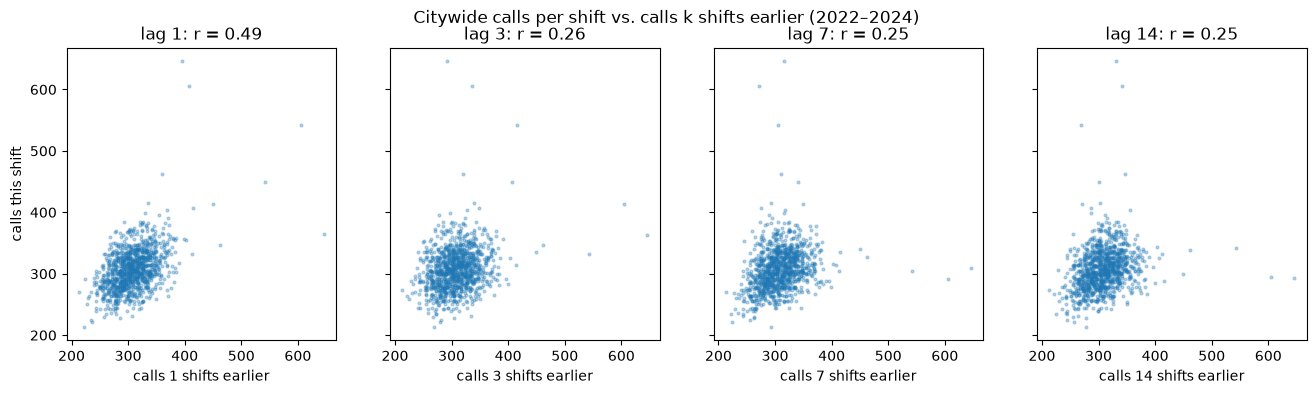

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8), sharey=True)
for ax, k in zip(axes, [1, 3, 7, 14]):
    ax.scatter(city.shift(k), city, s=4, alpha=0.3)
    ax.set_title(f'lag {k}: r = {city.corr(city.shift(k)):.2f}')
    ax.set_xlabel(f'calls {k} shifts earlier')
axes[0].set_ylabel('calls this shift')
fig.suptitle('Citywide calls per shift vs. calls k shifts earlier (2022–2024)')
fig.savefig('../figures/lag_plots.png', dpi=200, bbox_inches='tight')
plt.show()


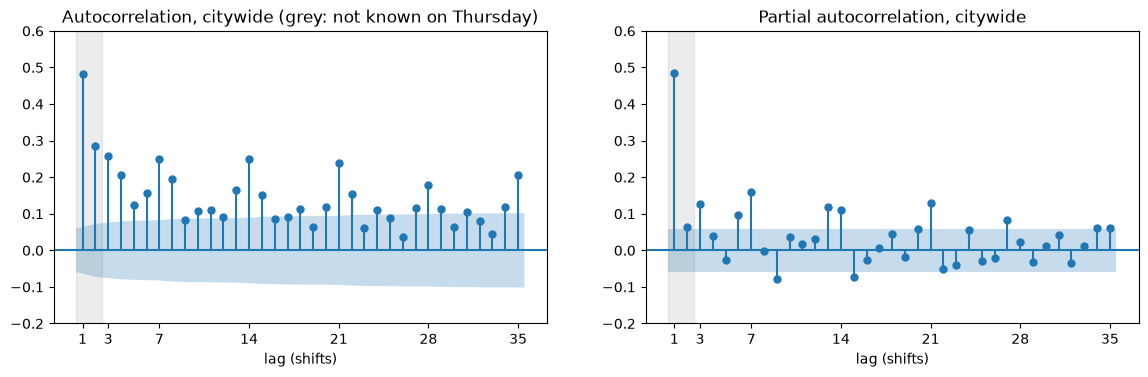

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
plot_acf(city, lags=35, missing='conservative', zero=False, ax=axes[0])
# plot_pacf cannot skip missing values, so fill the few outage shifts from their neighbours
plot_pacf(city.interpolate(), lags=35, method='ywm', zero=False, ax=axes[1])
for ax in axes:
    ax.axvspan(0.5, 2.5, color='grey', alpha=0.15)      # lags 1-2 are not known on Thursday
    ax.set_xticks([1, 3, 7, 14, 21, 28, 35])
    ax.set_xlabel('lag (shifts)')
    ax.set_ylim(-0.2, 0.6)
axes[0].set_title('Autocorrelation, citywide (grey: not known on Thursday)')
axes[1].set_title('Partial autocorrelation, citywide')
fig.savefig('../figures/acf_pacf_city.png', dpi=200, bbox_inches='tight')
plt.show()


In [10]:
# remove each station's own mean, so busy and quiet stations can be compared
# counts are whole numbers with many ties, which the mutual-information estimator overrates,
# so spread each count over its unit interval before comparing
rng = np.random.default_rng(0)
train['resid'] = train['known'] + rng.uniform(-0.5, 0.5, len(train)) - train.groupby('Station')['known'].transform('mean')

lags = [3, 4, 5, 6, 7, 14, 21, 28]
X = pd.concat({f'lag{k}': train.groupby('Station')['resid'].shift(k) for k in lags}, axis=1)
ok = X.notna().all(axis=1) & train['resid'].notna()
mi = pd.Series(mutual_info_regression(X[ok], train.loc[ok, 'resid'], random_state=0), index=X.columns)
station_acf = pd.Series({f'lag{k}': train['resid'].corr(train.groupby('Station')['resid'].shift(k)) for k in lags})
pd.DataFrame({'autocorrelation': station_acf, 'mutual information': mi}).round(3)

,autocorrelation,mutual information
lag3,0.072,0.023
lag4,0.053,0.029
lag5,0.047,0.023
lag6,0.046,0.030
lag7,0.068,0.019
lag14,0.072,0.031
lag21,0.067,0.027
lag28,0.056,0.022


## What we choose

| Finding | Feature |
|---|---|
| Partial autocorrelation is significant at lag 3 | `lag3` |
| Peaks at lags 7, 14, 21, 28 (weekly pattern) | `lag7`, `same_weekday_avg4` (mean of lags 7, 14, 21, 28) |
| Autocorrelation fades slowly (a slowly changing level) | `avg28` (mean of lags 3–30) |
| Single-station correlations are weak and noisy | averages (`avg7`, `avg28`) are steadier than single days |
| Partial autocorrelation near 0 at lags 4, 5, 8 | no separate features for these lags |

Mutual information is about the same for every lag (0.02–0.03), so we find no non-linear dependence beyond what the correlations show.
